In [13]:
import numpy as np
import pandas as pd
import pandas_ta as ta
from Engine.DataTimeseries import DataTimeseries
from Engine.Backtester import Backtester

In [14]:
data = DataTimeseries('./Data/nq_continous.csv')
data.resample_data('15min')
in_sample, out_of_sample = data.split(pd.Timestamp(year=2023, month=1, day=1))


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows



In [15]:
close = in_sample.get_close_prices_series()

# N and 4N pairs
ema_8 = ta.hma(close, 8)
ema_32 = ta.hma(close, 32)
ema_16 = ta.hma(close, 16)
ema_64 = ta.hma(close, 64)
ema_128 = ta.hma(close, 128)
ema_256 = ta.hma(close, 256)

# df = pd.concat(
#     [ema_8, ema_16, ema_32, ema_64, ema_128, ema_256, close],
#     axis=1
# ).dropna()

# ema_8, ema_16, ema_32, ema_64, ema_128, ema_256, close = df.T.values

emsd = pd.Series(close).ewm(span=32, adjust=False).std()

# calculate forecasts
signal_8_32 = (ema_8 - ema_32)
signal_16_64 = (ema_16 - ema_64)
signal_32_128 = (ema_32 - ema_128)
signal_64_256 = (ema_64 - ema_256)

raw_forecast_8_32 = signal_8_32 / emsd
raw_forecast_16_64 = signal_16_64 / emsd
raw_forecast_32_128 = signal_32_128 / emsd
raw_forecast_64_256 = signal_64_256 / emsd


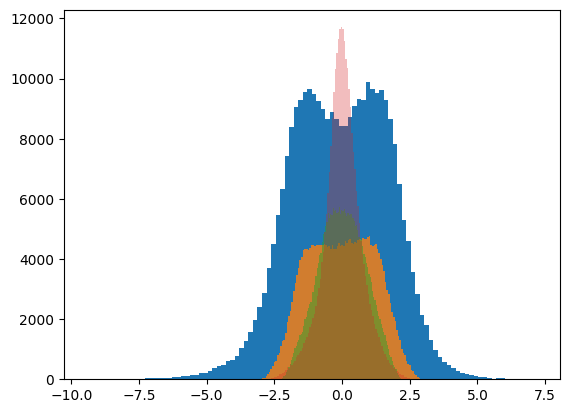

count    293953.000000
mean          0.006813
std           0.701032
min          -2.773441
25%          -0.382521
50%           0.002611
75%           0.410635
max           2.779104
dtype: float64

In [16]:
import matplotlib.pyplot as plt
# print(ema_8.value_counts())
plt.hist(raw_forecast_64_256.values, bins=100, alpha=1)
plt.hist(raw_forecast_32_128.values, bins=100, alpha=0.8)
plt.hist(raw_forecast_16_64.values, bins=100, alpha=0.5)
plt.hist(raw_forecast_8_32.values, bins=100, alpha=0.3)


# rolling_mean = raw_forecast_8_32.rolling(500).mean()
# rolling_std =raw_forecast_8_32.rolling(500).std()
# plt.plot(rolling_mean)
# plt.plot(rolling_std)
plt.show()
raw_forecast_8_32.describe()

In [19]:
import optuna

weight_start = -30
weight_end = 30
no_trade_range = 20
np_8_32 = raw_forecast_8_32.to_numpy(dtype=np.float32)
np_16_64 = raw_forecast_16_64.to_numpy(dtype=np.float32)
np_32_128 = raw_forecast_32_128.to_numpy(dtype=np.float32)
np_64_256 = raw_forecast_64_256.to_numpy(dtype=np.float32)

# clip_min = -20
# clip_max = 20
# np_8_32 = np.clip(np_8_32, clip_min, clip_max)
# np_16_64 = np.clip(np_16_64, clip_min, clip_max)
# np_32_128 = np.clip(np_32_128, clip_min, clip_max)
# np_64_256 = np.clip(np_64_256, clip_min, clip_max)

trials = 3000

def generate_signal(w1, w2, w3, w4):
    combined_forecast = np_8_32 * w1 + np_16_64 * w2 + np_32_128 * w3 + np_64_256 * w4
    # combined_forecast = combined_forecast / clip_max
    # combined_forecast = np.pad(combined_forecast, (256, 0), constant_values=np.nan)
    signal = np.zeros_like(combined_forecast, dtype=np.float32)

    # long_pos = combined_forecast > w4
    # short_pos = combined_forecast < -w4
    signal[combined_forecast > 0] = 1
    signal[combined_forecast < 0] = -1

    # signal[long_pos] = combined_forecast[long_pos]
    # signal[short_pos] = combined_forecast[short_pos]
    # # signal[d] = combined_forecast
    # signal[combined_forecast < -w4] = combined_forecast

    # off by one drop first of signal
    # signal = signal[1:]
    # print(signal.shape, combined_forecast.shape, in_sample.get_ohlc_prices().shape)
    return pd.Series(signal)

def objective(trial):
    w1 = trial.suggest_float('w1', weight_start, weight_end)
    w2 = trial.suggest_float('w2', weight_start, weight_end)
    w3 = trial.suggest_float('w3', weight_start, weight_end)
    w4 = trial.suggest_float('w4', weight_start, weight_end)

    bt = Backtester(in_sample.get_ohlc_prices(), in_sample.get_indicies(), generate_signal(w1, w2, w3, w4).values, in_sample.get_timeframe(), tick_value=1.25, contract_multiplier=5, initial_equity=100000, commission=0.25, slippage_ticks=4)
    bt.quick_backtest()

    return -bt.final_equity 

study = optuna.create_study()
study.optimize(objective, n_trials=trials)
print(study.best_params)
print(-study.best_value)


[I 2026-01-02 13:51:09,427] A new study created in memory with name: no-name-d65e7136-074e-44fa-8aef-44f1488cde43
[I 2026-01-02 13:51:09,440] Trial 0 finished with value: -2582.625 and parameters: {'w1': -17.79769089696763, 'w2': 28.89597232104193, 'w3': 26.288295239925006, 'w4': -2.29178726828858}. Best is trial 0 with value: -2582.625.
[I 2026-01-02 13:51:09,449] Trial 1 finished with value: 1668.125 and parameters: {'w1': -7.179213252151346, 'w2': 4.922539726481901, 'w3': -9.450896140039372, 'w4': -16.81509271877228}. Best is trial 0 with value: -2582.625.
[I 2026-01-02 13:51:09,456] Trial 2 finished with value: -64219.125 and parameters: {'w1': 10.81680486894789, 'w2': -9.264731809321386, 'w3': -18.247723155224236, 'w4': 9.605711041268606}. Best is trial 2 with value: -64219.125.
[I 2026-01-02 13:51:09,464] Trial 3 finished with value: -125263.125 and parameters: {'w1': 4.354122024722329, 'w2': -21.60218959759818, 'w3': -2.3834324560568696, 'w4': 29.638665873562935}. Best is trial 

{'w1': 1.3255829220952307, 'w2': 1.3538776541002848, 'w3': -11.50307031445369, 'w4': 27.625824225060292}
172382.625


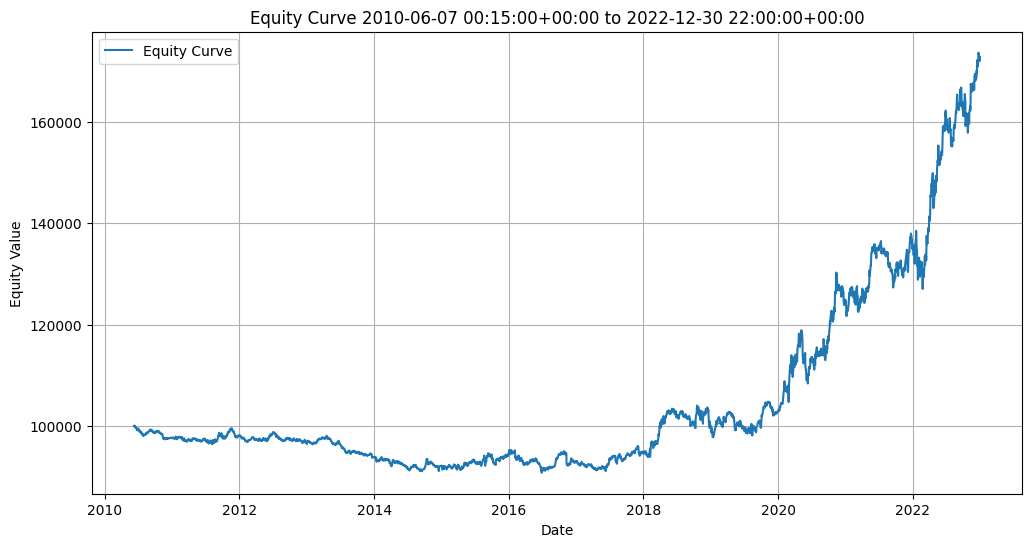

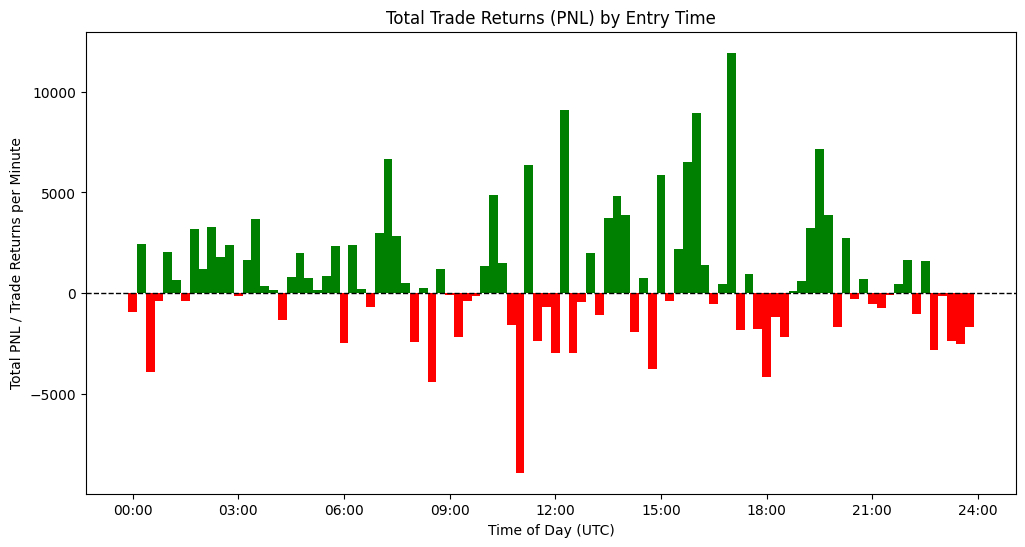

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

c:\Users\ryany\OneDrive\Desktop\Futures-PC\MacLink\RugbeatunoBacktestingSuite\Engine\Backtester.py:537: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_left.legend()
c:\Users\ryany\OneDrive\Desktop\Futures-PC\MacLink\RugbeatunoBacktestingSuite\Engine\Backtester.py:558: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\ryany\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


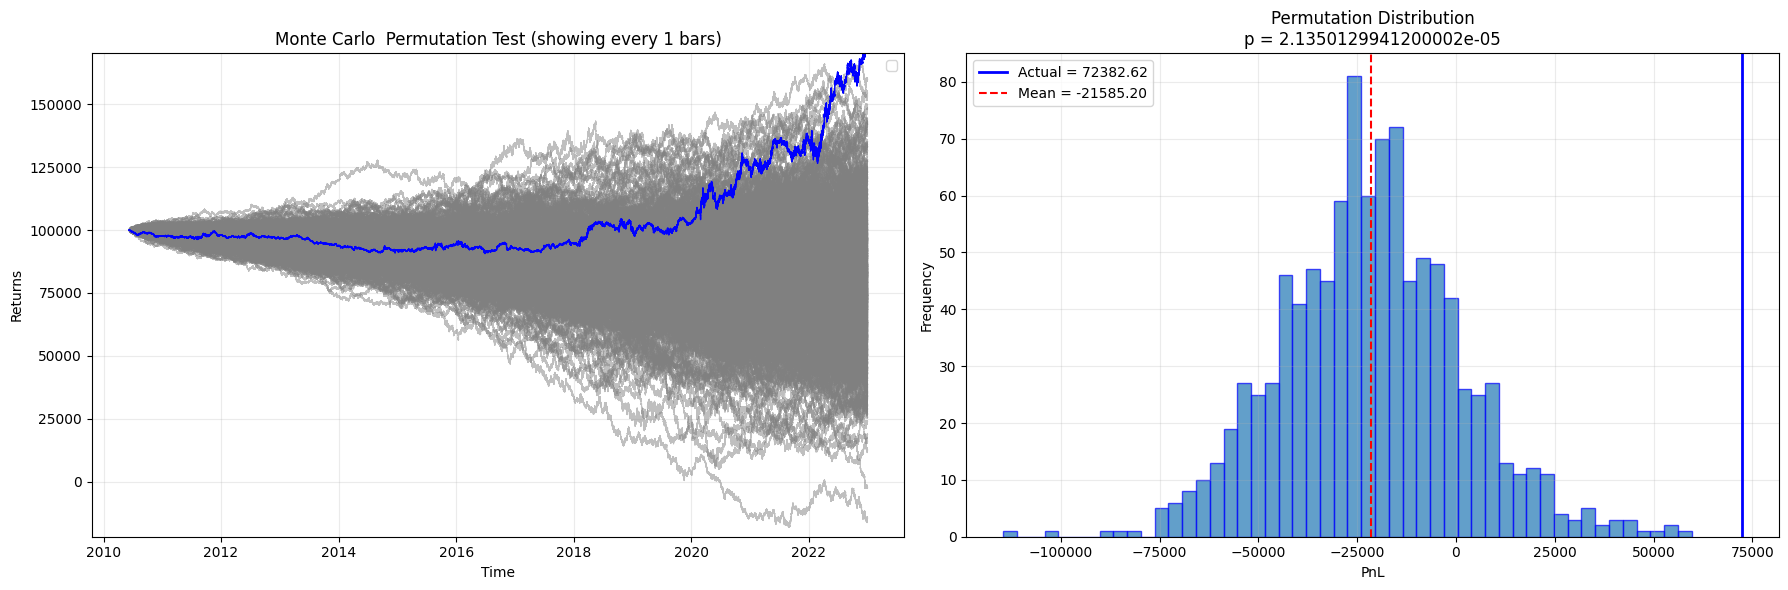


        Backtest Results from 2010-06-07 00:15:00+00:00 to 2022-12-30 22:00:00+00:00 (4589 days 21:45:00)
        Equity:     $100,000.00 -> $172,382.62
        Buy & Hold: $100,000.00 -> $606,106.77
        Buy & Hold Return (%): 506.11%
        Strategy Return (%):   72.38%

        Total Trades:     4001.00
        Win Rate:         40.39%
        95% CI:           38.88% - 41.92%
        Avg. Win:         $336.45
        Avg. Loss:        $-197.70
        Ratio Win/Loss:   1.70
        Expected Value:   $18.04

        Largest Win:      $5,229.75
        Largest Loss:     $-4,834.00
        Max Consec. Wins: 14
        Max Consec. Loss: 14

        Max Drawdown from 2022-01-19 05:30:00+00:00 to 2022-02-23 17:30:00+00:00 (35 days 12:00:00)
        Max Drawdown:     $-13,021.25
        Max Drawdown (%): -7.46%

        Slippage:   4 ticks
        Commission: $0.25
        Contract Multiplier: $5.00
        Transaction Costs:   $20,997.38

        CAGR:              4.43%
        Sha

In [20]:
w1 = 1.3255829220952307
w2 = 1.3538776541002848
w3 = -11.50307031445369
w4 = 27.625824225060292
signal_series = generate_signal(
    w1, w2, w3, w4)


bt = Backtester(in_sample.get_ohlc_prices(), in_sample.get_indicies(), generate_signal(w1, w2, w3, w4).values, in_sample.get_timeframe(), tick_value=1.25, contract_multiplier=5, initial_equity=100000, commission=0.25, slippage_ticks=4)
bt.full_backtest()
bt.generate_equity_curve().plot()
bt.generate_trade_time_distribution()
bt.monte_carlo_permutation_test(iterations=1000, pct_of_trades=1)
print(bt)
